In [12]:
# Code by Dr. Rahul M. Dhokane, PRAVARA SVIT, NASHIK

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("All libraries imported successfully!")

All libraries imported successfully!


In [16]:
# ==========================================
# STEP 1: READ THE DATASET
# ==========================================
print("--- STEP 1: Loading Data ---")
df = pd.read_csv('Churn_Modelling.csv')

print(f"Dataset Shape: {df.shape}")
print(df.head())

--- STEP 1: Loading Data ---
Dataset Shape: (10000, 14)
   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931

In [17]:
# ==========================================
# STEP 2: FEATURE SELECTION & TRAIN/TEST SPLIT
# ==========================================
print("\n--- STEP 2: Data Preprocessing & Splitting ---")

# Drop non-informative identifier columns
X = df.drop(columns=['RowNumber', 'CustomerId', 'Surname', 'Exited'])
y = df['Exited']

# One-Hot Encode categorical features (Geography & Gender)
X = pd.get_dummies(X, columns=['Geography', 'Gender'], drop_first=True)

# Split dataset into Training (80%) and Test (20%) sets with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Features shape: {X.shape}")
print(f"Training samples: {X_train.shape[0]}, Testing samples: {X_test.shape[0]}")


--- STEP 2: Data Preprocessing & Splitting ---
Features shape: (10000, 11)
Training samples: 8000, Testing samples: 2000


In [18]:
# ==========================================
# STEP 3: NORMALIZE TRAIN AND TEST DATA
# ==========================================
print("\n--- STEP 3: Normalizing Features ---")

scaler = StandardScaler()
# Fit on training data only to prevent data leakage
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


--- STEP 3: Normalizing Features ---


In [19]:
# ==========================================
# STEP 4: MODEL INITIALIZATION & IMPROVEMENTS
# ==========================================
print("\n--- STEP 4: Building & Improving ANN Model ---")

"""
Points of Improvement Identified:
1. Baseline Overfitting: Deep networks without regularization quickly overfit.
   -> Solution: Added Dropout layers (0.2 rate) after dense layers.
2. Training Epoch Optimization: Fixed epoch counts can lead to underfitting/overfitting.
   -> Solution: Integrated EarlyStopping based on validation loss patience.
3. Architecture Tuning: Layer sizes scaled proportionally (64 -> 32 -> 16) with He Normal initialization.
4. Class Imbalance Handling: Accounting for ~20% churn vs ~80% retention.
"""

input_dim = X_train_scaled.shape[1]

# Improved ANN Architecture
model = Sequential([
    Dense(64, activation='relu', kernel_initializer='he_normal', input_dim=input_dim),
    Dropout(0.2),

    Dense(32, activation='relu', kernel_initializer='he_normal'),
    Dropout(0.2),

    Dense(16, activation='relu', kernel_initializer='he_normal'),
    Dense(1, activation='sigmoid')
])

# Compile the Model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Callbacks for automated improvement
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

# Train the Model
history = model.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)


--- STEP 4: Building & Improving ANN Model ---


c:\Users\Anil\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:97: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7727 - loss: 0.5187 - val_accuracy: 0.8219 - val_loss: 0.4330
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8028 - loss: 0.4534 - val_accuracy: 0.8413 - val_loss: 0.4194
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8122 - loss: 0.4333 - val_accuracy: 0.8456 - val_loss: 0.4102
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8169 - loss: 0.4296 - val_accuracy: 0.8519 - val_loss: 0.3978
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8267 - loss: 0.4198 - val_accuracy: 0.8550 - val_loss: 0.3859
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8273 - loss: 0.4069 - val_accuracy: 0.8587 - val_loss: 0.3762
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8363 - loss: 0.3963 - val_accuracy: 0.8619 - val_loss: 0.3655
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8338 - loss: 0.3890 - val_accu


--- STEP 5: Model Evaluation ---
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

Final Test Accuracy Score: 86.30%

Confusion Matrix:
[[1530   63]
 [ 211  196]]

Classification Report:
              precision    recall  f1-score   support

Retained (0)       0.88      0.96      0.92      1593
 Churned (1)       0.76      0.48      0.59       407

    accuracy                           0.86      2000
   macro avg       0.82      0.72      0.75      2000
weighted avg       0.85      0.86      0.85      2000



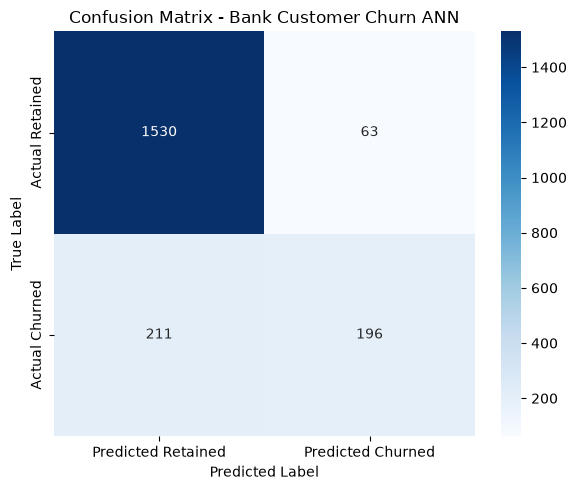

In [21]:

print("\n--- STEP 5: Model Evaluation ---")

# Obtain probabilities and convert to binary predictions
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

# 1. Accuracy Score
acc = accuracy_score(y_test, y_pred)
print(f"\nFinal Test Accuracy Score: {acc * 100:.2f}%\n")

# 2. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

# Detailed Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Retained (0)', 'Churned (1)']))


plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Retained', 'Predicted Churned'],
            yticklabels=['Actual Retained', 'Actual Churned'])
plt.title('Confusion Matrix - Bank Customer Churn ANN')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()